Kích thước tập Train: 5,892 mẫu | Tập Test: 1,473 mẫu

🏆 BẢNG SO SÁNH HIỆU NĂNG 4 MÔ HÌNH TRÊN TẬP TEST:


,Mô hình,MAE (Tỷ VNĐ),RMSE (Tỷ VNĐ),R² Score
3,4. Gradient Boosting Regressor,1.917,4.024,0.6399
2,3. Random Forest Regressor,2.047,4.790,0.4897
1,2. Ridge Regression,2.459,4.829,0.4814
0,1. Linear Regression (Baseline),2.486,5.046,0.4338


💾 Đã lưu mô hình tốt nhất (4. Gradient Boosting Regressor) tại: ../models\best_hanoi_housing_model.pkl


C:\Users\nguye\AppData\Local\Temp\ipykernel_21388\3879340822.py:125: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=imp_series.values, y=imp_series.index, ax=axes[1], palette="viridis")


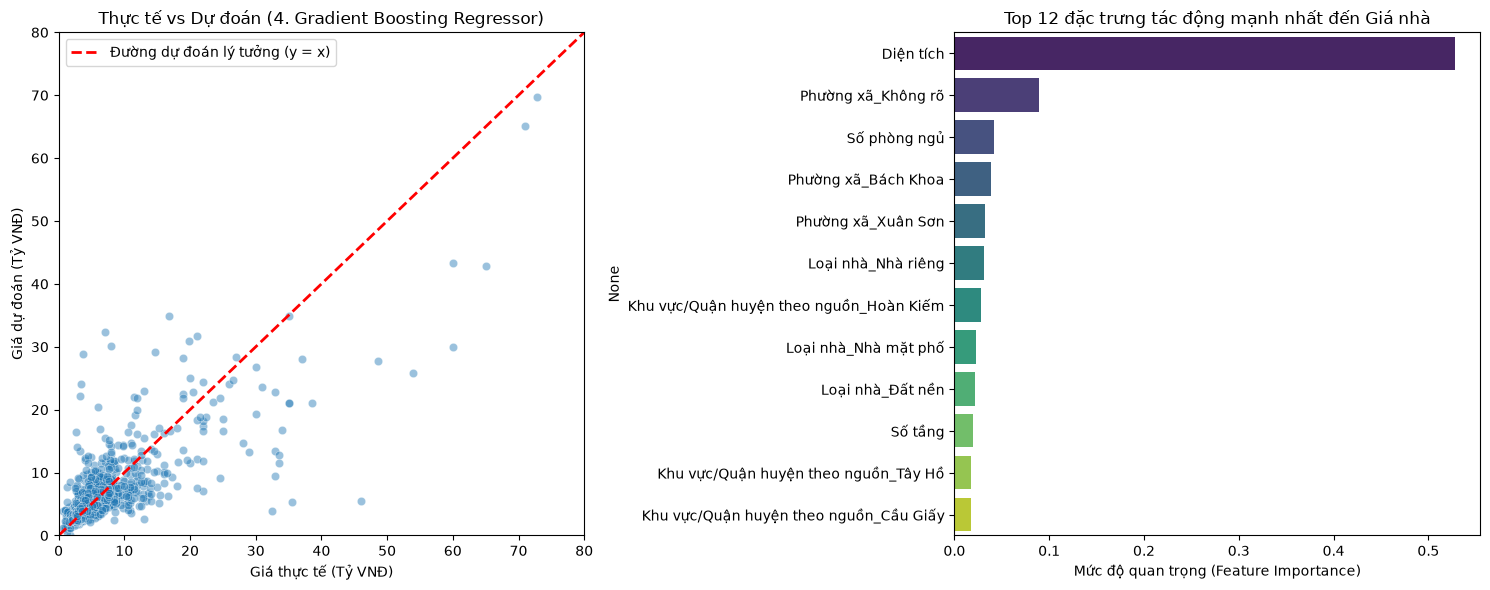

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# 1. Nạp tập dữ liệu sạch (7.365 bản ghi đạt chuẩn 3 cờ = 0)
proc_dir = "../Data/processed" if os.path.exists("../Data/processed") else "Data/processed"
df = pd.read_csv(os.path.join(proc_dir, "hanoi_housing_cleaned.csv"))

# Tạo biến mục tiêu: Giá nhà theo đơn vị Tỷ VNĐ (dễ diễn giải sai số MAE/RMSE)
df["Gia_Ty_VND"] = df["Giá chuẩn hóa VNĐ"] / 1e9

# Chọn nhóm đặc trưng đầu vào (Features) & biến mục tiêu (Target)
num_features = ["Diện tích", "Số tầng", "Số phòng ngủ", "Số phòng vệ sinh"]
cat_features = ["Khu vực/Quận huyện theo nguồn", "Phường xã", "Loại nhà"]

X = df[num_features + cat_features].copy()
y = df["Gia_Ty_VND"].copy()

# 2. Chia tập Train (80%) và Test (20%) trước mọi bước biến đổi để chống Data Leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"Kích thước tập Train: {len(X_train):,} mẫu | Tập Test: {len(X_test):,} mẫu")

# 3. Xây dựng Pipeline tiền xử lý (fit độc lập trên tập Train)
num_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Không rõ")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_transformer, num_features),
        ("cat", cat_transformer, cat_features),
    ]
)

# 4. Khai báo 4 mô hình hồi quy để so sánh
models = {
    "1. Linear Regression (Baseline)": LinearRegression(),
    "2. Ridge Regression": Ridge(alpha=10.0, random_state=42),
    "3. Random Forest Regressor": RandomForestRegressor(
        n_estimators=200, max_depth=18, min_samples_leaf=3, random_state=42, n_jobs=-1
    ),
    "4. Gradient Boosting Regressor": GradientBoostingRegressor(
        n_estimators=250, learning_rate=0.08, max_depth=5, random_state=42
    ),
}

results = []
trained_pipelines = {}

for name, model in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", model)
    ])
    pipe.fit(X_train, y_train)
    y_pred = np.maximum(pipe.predict(X_test), 0.1)  # Chặn giá dự đoán âm

    mae = mean_absolute_error(y_test, y_pred)
    rmse = root_mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Mô hình": name,
        "MAE (Tỷ VNĐ)": round(mae, 3),
        "RMSE (Tỷ VNĐ)": round(rmse, 3),
        "R² Score": round(r2, 4)
    })
    trained_pipelines[name] = pipe

df_results = pd.DataFrame(results).sort_values(by="R² Score", ascending=False)
print("\n🏆 BẢNG SO SÁNH HIỆU NĂNG 4 MÔ HÌNH TRÊN TẬP TEST:")
display(df_results)

# 5. Lưu mô hình tốt nhất để phục vụ báo cáo / triển khai
best_model_name = df_results.iloc[0]["Mô hình"]
best_pipe = trained_pipelines[best_model_name]
model_dir = "../models" if os.path.exists("../Data") else "models"
os.makedirs(model_dir, exist_ok=True)
model_path = os.path.join(model_dir, "best_hanoi_housing_model.pkl")
joblib.dump(best_pipe, model_path)
print(f"💾 Đã lưu mô hình tốt nhất ({best_model_name}) tại: {model_path}")

# 6. Trực quan hóa: Giá thực tế vs Giá dự đoán & Mức độ quan trọng của đặc trưng
y_pred_best = np.maximum(best_pipe.predict(X_test), 0.1)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Biểu đồ 1: Actual vs Predicted
sns.scatterplot(x=y_test, y=y_pred_best, alpha=0.45, ax=axes[0], color="#1f77b4")
max_val = min(max(y_test.max(), y_pred_best.max()), 80)
axes[0].plot([0, max_val], [0, max_val], "r--", lw=2, label="Đường dự đoán lý tưởng (y = x)")
axes[0].set_xlim(0, max_val)
axes[0].set_ylim(0, max_val)
axes[0].set_title(f"Thực tế vs Dự đoán ({best_model_name})")
axes[0].set_xlabel("Giá thực tế (Tỷ VNĐ)")
axes[0].set_ylabel("Giá dự đoán (Tỷ VNĐ)")
axes[0].legend()

# Biểu đồ 2: Top 12 đặc trưng ảnh hưởng mạnh nhất đến giá nhà
reg = best_pipe.named_steps["regressor"]
if hasattr(reg, "feature_importances_"):
    ohe_cols = best_pipe.named_steps["preprocessor"].named_transformers_["cat"].named_steps["onehot"].get_feature_names_out(cat_features)
    all_feature_names = num_features + list(ohe_cols)
    imp_series = pd.Series(reg.feature_importances_, index=all_feature_names).sort_values(ascending=False).head(12)
    sns.barplot(x=imp_series.values, y=imp_series.index, ax=axes[1], palette="viridis")
    axes[1].set_title("Top 12 đặc trưng tác động mạnh nhất đến Giá nhà")
    axes[1].set_xlabel("Mức độ quan trọng (Feature Importance)")

plt.tight_layout()
plt.show()

Tổng số mẫu sạch: 7,365 | Tập Train: 5,892 (80%) | Tập Test: 1,473 (20%)

🏆 BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH TRÊN TẬP TEST:


,Mô hình,MAE (VNĐ),RMSE (VNĐ),MAE (Tỷ VNĐ),RMSE (Tỷ VNĐ),R² Score
0,3. CatBoost,"1,954,023,892","4,240,648,047",1.954,4.241,0.6001
1,1. Ridge Regression,"2,432,630,930","4,715,987,951",2.433,4.716,0.5054
2,2. Random Forest,"2,047,666,370","4,797,443,253",2.048,4.797,0.4882
3,0. Baseline (Trung vị tập Train),"2,922,807,094","6,979,330,716",2.923,6.979,-0.0833


💾 Đã lưu mô hình tốt nhất [3. CatBoost] tại: ../models\best_housing_model.pkl


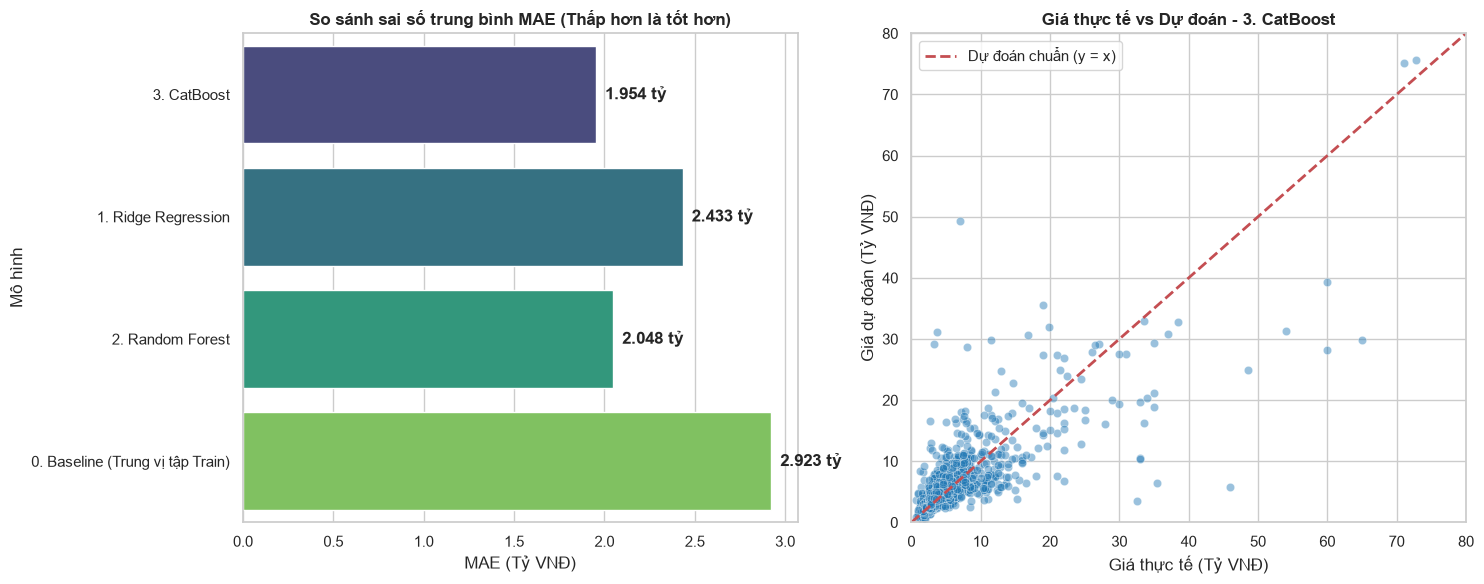

In [2]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from catboost import CatBoostRegressor

plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial"]
plt.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid")

# ==============================================================================
# 1. NẠP DỮ LIỆU SẠCH & XÁC ĐỊNH ĐẦU VÀO / ĐẦU RA THEO ĐỀ BÀI
# ==============================================================================
proc_dir = "../Data/processed" if os.path.exists("../Data/processed") else "Data/processed"
df = pd.read_csv(os.path.join(proc_dir, "hanoi_housing_cleaned.csv"))

# Đầu vào bắt buộc: Vị trí, diện tích, loại nhà
mandatory_features = ["Khu vực/Quận huyện theo nguồn", "Phường xã", "Diện tích", "Loại nhà"]
# Đầu vào bổ sung: Số tầng, số phòng ngủ, số phòng vệ sinh, tên dự án
optional_features = ["Số tầng", "Số phòng ngủ", "Số phòng vệ sinh", "Tên dự án nếu có"]

num_cols = ["Diện tích", "Số tầng", "Số phòng ngủ", "Số phòng vệ sinh"]
cat_cols = ["Khu vực/Quận huyện theo nguồn", "Phường xã", "Loại nhà", "Tên dự án nếu có"]

X = df[mandatory_features + optional_features].copy()
y = df["Giá chuẩn hóa VNĐ"].copy()  # Đầu ra: đơn vị VNĐ

# ==============================================================================
# 2. CHIA TẬP TRAIN / TEST (80% - 20%) TRƯỚC KHI TIỀN XỬ LÝ (CHỐNG DATA LEAKAGE)
# ==============================================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"Tổng số mẫu sạch: {len(X):,} | Tập Train: {len(X_train):,} (80%) | Tập Test: {len(X_test):,} (20%)")

# Pipeline tiền xử lý cho các mô hình Scikit-Learn (Baseline, Ridge, Random Forest)
num_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Không rõ")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_transformer, num_cols),
        ("cat", cat_transformer, cat_cols)
    ]
)

# ==============================================================================
# 3. HUẤN LUYỆN MÔ HÌNH CƠ SỞ & 3 MÔ HÌNH SO SÁNH
# ==============================================================================
sklearn_models = {
    "0. Baseline (Trung vị tập Train)": DummyRegressor(strategy="median"),
    "1. Ridge Regression": Ridge(alpha=10.0, random_state=42),
    "2. Random Forest": RandomForestRegressor(
        n_estimators=200, max_depth=18, min_samples_leaf=3, random_state=42, n_jobs=-1
    ),
}

results = []
predictions = {}
saved_artifacts = {}

def evaluate_predictions(model_name, y_true, y_pred):
    y_pred_clean = np.maximum(y_pred, 1e8)  # Đảm bảo giá dự đoán không âm
    mae = mean_absolute_error(y_true, y_pred_clean)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred_clean))
    r2 = r2_score(y_true, y_pred_clean)
    results.append({
        "Mô hình": model_name,
        "MAE (VNĐ)": mae,
        "RMSE (VNĐ)": rmse,
        "MAE (Tỷ VNĐ)": round(mae / 1e9, 3),
        "RMSE (Tỷ VNĐ)": round(rmse / 1e9, 3),
        "R² Score": round(r2, 4)
    })
    predictions[model_name] = y_pred_clean

# Huấn luyện Baseline, Ridge, Random Forest
for name, regressor in sklearn_models.items():
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("model", regressor)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    evaluate_predictions(name, y_test, y_pred)
    saved_artifacts[name] = pipe

# Huấn luyện CatBoost (xử lý trực tiếp biến phân loại cat_features)
X_train_cb = X_train.copy()
X_test_cb = X_test.copy()

# Fit median chỉ trên X_train để điền thiếu cột số cho CatBoost
train_medians = X_train_cb[num_cols].median()
X_train_cb[num_cols] = X_train_cb[num_cols].fillna(train_medians)
X_test_cb[num_cols] = X_test_cb[num_cols].fillna(train_medians)

for col in cat_cols:
    X_train_cb[col] = X_train_cb[col].fillna("Không rõ").astype(str)
    X_test_cb[col] = X_test_cb[col].fillna("Không rõ").astype(str)

cb_model = CatBoostRegressor(
    iterations=600,
    learning_rate=0.08,
    depth=6,
    loss_function="RMSE",
    random_seed=42,
    verbose=0
)
cb_model.fit(X_train_cb, y_train, cat_features=cat_cols)
y_pred_cb = cb_model.predict(X_test_cb)
evaluate_predictions("3. CatBoost", y_test, y_pred_cb)
saved_artifacts["3. CatBoost"] = {
    "model": cb_model,
    "medians": train_medians.to_dict(),
    "num_cols": num_cols,
    "cat_cols": cat_cols
}

# ==============================================================================
# 4. BẢNG SO SÁNH KẾT QUẢ & LƯU MÔ HÌNH TỐT NHẤT
# ==============================================================================
df_results = pd.DataFrame(results).sort_values(by="R² Score", ascending=False).reset_index(drop=True)

df_display = df_results.copy()
df_display["MAE (VNĐ)"] = df_display["MAE (VNĐ)"].map("{:,.0f}".format)
df_display["RMSE (VNĐ)"] = df_display["RMSE (VNĐ)"].map("{:,.0f}".format)

print("\n🏆 BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH TRÊN TẬP TEST:")
display(df_display)

best_name = df_results.iloc[0]["Mô hình"]
model_dir = "../models" if os.path.exists("../Data") else "models"
os.makedirs(model_dir, exist_ok=True)
model_path = os.path.join(model_dir, "best_housing_model.pkl")
joblib.dump(saved_artifacts[best_name], model_path)
print(f"💾 Đã lưu mô hình tốt nhất [{best_name}] tại: {model_path}")

# ==============================================================================
# 5. BIỂU ĐỒ SO SÁNH SAI SỐ & GIÁ THỰC TẾ VS DỰ ĐOÁN
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Biểu đồ 1: So sánh MAE (Tỷ VNĐ) giữa 4 mô hình
sns.barplot(
    data=df_results, x="MAE (Tỷ VNĐ)", y="Mô hình",
    hue="Mô hình", legend=False, palette="viridis", ax=axes[0]
)
axes[0].set_title("So sánh sai số trung bình MAE (Thấp hơn là tốt hơn)", fontweight="bold")
for i, v in enumerate(df_results["MAE (Tỷ VNĐ)"]):
    axes[0].text(v + 0.05, i, f"{v:.3f} tỷ", va="center", fontweight="bold")

# Biểu đồ 2: Thực tế vs Dự đoán của mô hình tốt nhất
y_test_ty = y_test / 1e9
y_best_ty = predictions[best_name] / 1e9
sns.scatterplot(x=y_test_ty, y=y_best_ty, alpha=0.45, color="#1f77b4", ax=axes[1])
limit = min(max(y_test_ty.max(), y_best_ty.max()), 80)
axes[1].plot([0, limit], [0, limit], "r--", lw=2, label="Dự đoán chuẩn (y = x)")
axes[1].set_xlim(0, limit)
axes[1].set_ylim(0, limit)
axes[1].set_title(f"Giá thực tế vs Dự đoán - {best_name}", fontweight="bold")
axes[1].set_xlabel("Giá thực tế (Tỷ VNĐ)")
axes[1].set_ylabel("Giá dự đoán (Tỷ VNĐ)")
axes[1].legend()

plt.tight_layout()
plt.show()

Kết quả so sánh trên tập kiểm thử (20% Test):

Baseline (Trung vị tập Train): MAE = 2,923 tỷ VNĐ (mốc tham chiếu cơ sở).

Ridge Regression: MAE = 2,433 tỷ VNĐ (giảm 16,8% sai số so với Baseline).

Random Forest: MAE = 2,048 tỷ VNĐ (giảm 29,9% sai số so với Baseline).

CatBoost (Được chọn): MAE = 1,954 tỷ VNĐ (thấp nhất trong cả 4 mô hình, giảm 33,1% sai số trung bình so với Baseline).

Lý do chọn CatBoost làm mô hình chính thức:

Độ chính xác cao nhất: Đạt sai số tuyệt đối trung bình (MAE) thấp nhất trên tập dữ liệu kiểm thử độc lập.

Xử lý tối ưu biến phân loại (Categorical Features): Dữ liệu bất động sản Hà Nội phụ thuộc rất mạnh vào các biến định danh nhiều nhãn như Quận/Huyện, Phường/Xã, Loại nhà, Tên dự án. CatBoost sử dụng cơ chế mã hóa mục tiêu có thứ tự (Ordered Target Statistics) nên khai thác trực tiếp các đặc trưng vị trí này mà không bị bùng nổ số chiều hay mất mát thông tin như One-Hot Encoding.

Nắm bắt tốt quan hệ phi tuyến tính: Giá nhà thay đổi đột biến theo từng tổ hợp Vị trí × Diện tích × Loại hình (ví dụ nhà mặt phố trung tâm so với chung cư ngoại thành). Các thuật toán tuyến tính như Ridge không mô hình hóa được độ cong này, trong khi cây quyết định tăng cường độ dốc (Gradient Boosting) của CatBoost học tốt các ngưỡng phân tách phức tạp này.